**FilmTV Movie Genre Predictor**

**Cel:** Przewidywanie gatunku filmu na podstawie opisu fabuły + porównanie modelu własnego z pretrenowanym BERT-em

**Techniki:**
- Embeddingi słów GloVe + reprezentacja sekwencyjna (RNN/GRU)
- Sieci neuronowe z pętlą treningową
- BERT (`bert-base-uncased`) — fine-tuning z HuggingFace
- Klasyfikacja top-3: zwracamy trzy najbardziej prawdopodobne gatunki
- Analiza grafowa + wykrywanie społeczności networkx

**Dane:**
- *Trening/ewaluacja:*
  FilmTV movies dataset (~41 000 filmów) z Kaggle (źródło: https://www.kaggle.com/datasets/stefanoleone992/filmtv-movies-dataset)
  
- *Test generalizacji:*
  TMDB 5000 (~5 000 filmów) (źródło: https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv)


## 1. Instalacja bibliotek i importy

In [ ]:
!pip install -q nltk

In [ ]:
import nltk
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)

True

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import networkx as nx
from networkx.algorithms import community

from nltk import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report

from transformers import BertTokenizer, BertForSequenceClassification
from transformers import get_linear_schedule_with_warmup

from collections import Counter
import json, os, random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Urządzenie: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Urządzenie: cuda
GPU: Tesla T4


## 2. Eksploracja danych (EDA)

In [ ]:
from google.colab import files
files.upload()

In [ ]:
df = pd.read_csv("/content/filmtv_movies.csv")
print(f"Rozmiar datasetu: {df.shape}")
print(f"Kolumny: {df.columns.tolist()}")
df[['title', 'genre', 'description']].head(3)

Rozmiar datasetu: (41399, 19)
Kolumny: ['filmtv_id', 'title', 'year', 'genre', 'duration', 'country', 'directors', 'actors', 'avg_vote', 'critics_vote', 'public_vote', 'total_votes', 'description', 'notes', 'humor', 'rhythm', 'effort', 'tension', 'erotism']


,title,genre,description
0,Bugs Bunny's Third Movie: 1001 Rabbit Tales,Animation,"With two protruding front teeth, a slightly sl..."
1,18 anni tra una settimana,Drama,"Samantha, not yet eighteen, leaves the comfort..."
2,Ride a Wild Pony,Romantic,"In the Australia of the pioneers, a boy and a ..."


In [ ]:
df = df[['title', 'genre', 'description']].dropna()
df = df[df['description'].str.len() > 10].reset_index(drop=True)

print(f"Próbek po czyszczeniu: {len(df)}")
print(f"\nPrzykład:")
print(f"  Tytuł:  {df.iloc[0]['title']}")
print(f"  Rodzaj: {df.iloc[0]['genre']}")
print(f"  Opis:   {df.iloc[0]['description'][:120]}...")

Próbek po czyszczeniu: 39762

Przykład:
  Tytuł:  Bugs Bunny's Third Movie: 1001 Rabbit Tales
  Rodzaj: Animation
  Opis:   With two protruding front teeth, a slightly sly air and a certain penchant for carrots, Bugs Bunny is one of the most po...


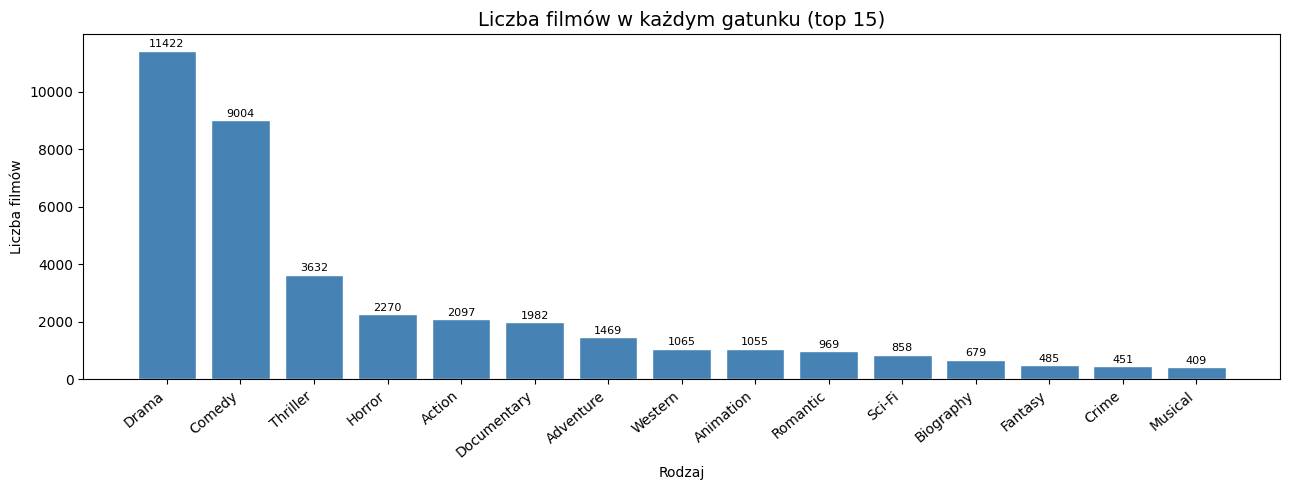

In [ ]:
genre_counts = Counter(df['genre'])

top15 = genre_counts.most_common(15)
genres_plot, counts_plot = zip(*top15)

plt.figure(figsize=(13, 5))
bars = plt.bar(genres_plot, counts_plot, color='steelblue', edgecolor='white')
plt.title('Liczba filmów w każdym gatunku (top 15)', fontsize=14)
plt.xlabel('Rodzaj')
plt.ylabel('Liczba filmów')
plt.xticks(rotation=40, ha='right')
for bar, cnt in zip(bars, counts_plot):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             str(cnt), ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('01_genre_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

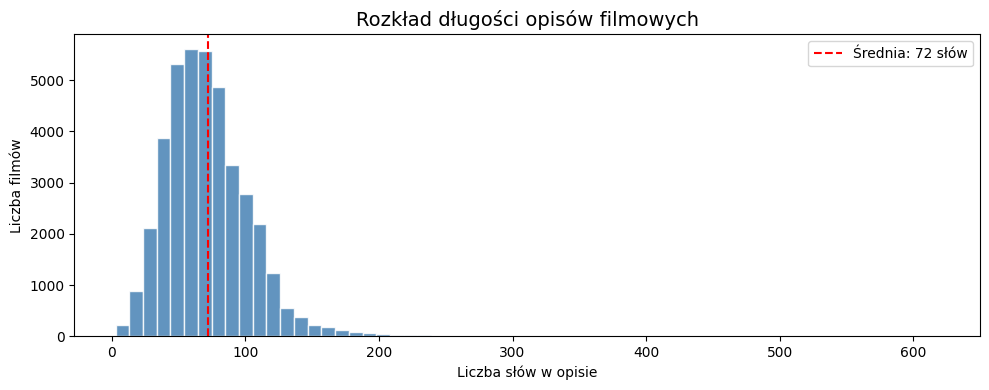

In [ ]:
df['desc_len'] = df['description'].str.split().str.len()

plt.figure(figsize=(10, 4))
plt.hist(df['desc_len'], bins=60, color='steelblue', edgecolor='white', alpha=0.85)
plt.axvline(df['desc_len'].mean(), color='red', linestyle='--',
            label=f"Średnia: {df['desc_len'].mean():.0f} słów")
plt.title('Rozkład długości opisów filmowych', fontsize=14)
plt.xlabel('Liczba słów w opisie')
plt.ylabel('Liczba filmów')
plt.legend()
plt.tight_layout()
plt.savefig('02_description_lengths.png', dpi=150, bbox_inches='tight')
plt.show()

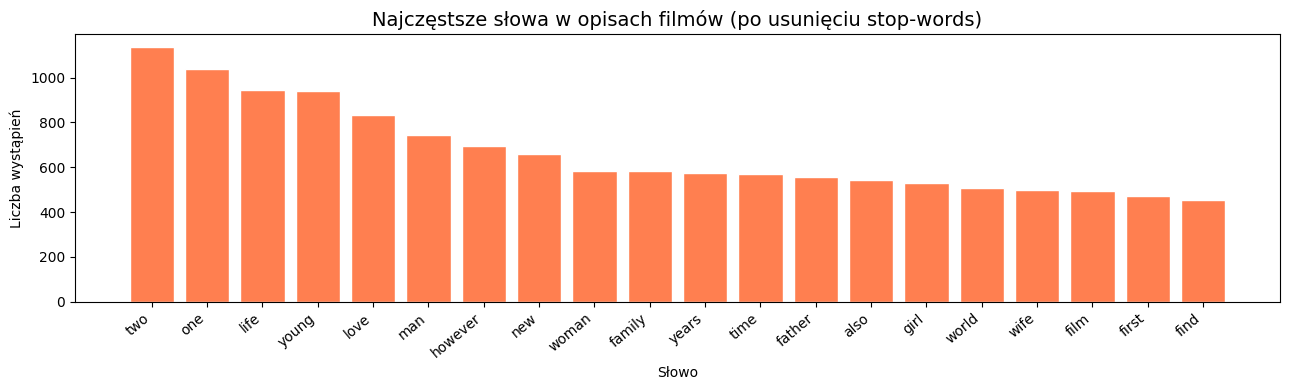

In [ ]:
stop_words_set = set(stopwords.words('english'))

word_counter = Counter()
for desc in df['description'].sample(5000, random_state=42):
    tokens = word_tokenize(desc.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words_set]
    word_counter.update(tokens)

words20, counts20 = zip(*word_counter.most_common(20))

plt.figure(figsize=(13, 4))
plt.bar(words20, counts20, color='coral', edgecolor='white')
plt.title('Najczęstsze słowa w opisach filmów (po usunięciu stop-words)', fontsize=14)
plt.xlabel('Słowo')
plt.ylabel('Liczba wystąpień')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.savefig('03_top_words.png', dpi=150, bbox_inches='tight')
plt.show()

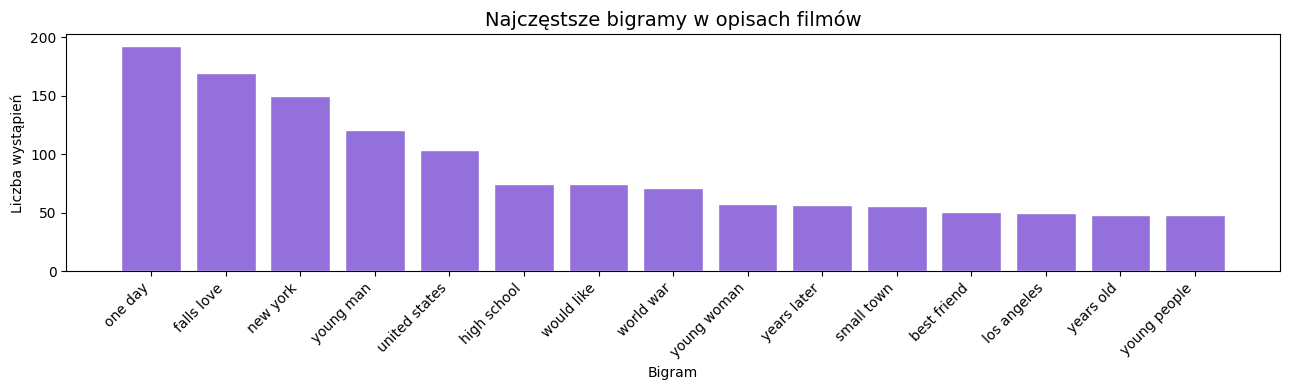

In [ ]:
#najczęstsze bigramy
from nltk import bigrams as nltk_bigrams

bigram_counter = Counter()
for desc in df['description'].sample(5000, random_state=42):
    tokens = word_tokenize(desc.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words_set]
    bigram_counter.update(nltk_bigrams(tokens))

top_bigrams = bigram_counter.most_common(15)
bigram_labels = [f"{a} {b}" for (a, b), _ in top_bigrams]
bigram_counts = [c for _, c in top_bigrams]

plt.figure(figsize=(13, 4))
plt.bar(bigram_labels, bigram_counts, color='mediumpurple', edgecolor='white')
plt.title('Najczęstsze bigramy w opisach filmów', fontsize=14)
plt.xlabel('Bigram')
plt.ylabel('Liczba wystąpień')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('04_top_bigrams.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Preprocessing tekstu

1. **Tokenizacja** — `word_tokenize`
2. **Filtrowanie** — tylko litery `.isalpha()`
3. **Stop-word** — usuwamy
4. **Lematyzacja** — forma podstawowa zgodna ze słownikiem GloVe


In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words_set = set(stopwords.words('english'))

#opis -> lista tokenów
def preprocess(text):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    tokens = [t for t in tokens if t not in stop_words_set]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

przyklad = df.iloc[0]['description']
print("PRZED:", przyklad[:150])
print("PO:   ", preprocess(przyklad)[:12])

PRZED: With two protruding front teeth, a slightly sly air and a certain penchant for carrots, Bugs Bunny is one of the most popular cartoon heroes, especial
PO:    ['two', 'protruding', 'front', 'teeth', 'slightly', 'sly', 'air', 'certain', 'penchant', 'carrot', 'bug', 'bunny']


In [ ]:
df['tokens'] = df['description'].apply(preprocess)
df = df[df['tokens'].map(len) > 0].reset_index(drop=True)
print(f"Próbek po preprocessingu: {len(df)}")

Próbek po preprocessingu: 39762


## 4. Kodowanie etykiet

Każdy film ma jeden gatunek —> klasyfikacja jednoetykietowa.

Etykiety kodujemy jako liczby całkowite: `Drama=0, Comedy=1, Thriller=2` itd.


In [ ]:
#wybieramy 10 najczęstszych gatunków
top_10 = 10
top_genres_list = [g for g, _ in genre_counts.most_common(top_10)]
print(f"Wybrane gatunki ({top_10}):")
for i, g in enumerate(top_genres_list, 1):
    print(f"  {i:2d}. {g}  ({genre_counts[g]:,} filmów)")

Wybrane gatunki (10):
   1. Drama  (11,422 filmów)
   2. Comedy  (9,004 filmów)
   3. Thriller  (3,632 filmów)
   4. Horror  (2,270 filmów)
   5. Action  (2,097 filmów)
   6. Documentary  (1,982 filmów)
   7. Adventure  (1,469 filmów)
   8. Western  (1,065 filmów)
   9. Animation  (1,055 filmów)
  10. Romantic  (969 filmów)


In [ ]:
#zostawiamy nasz top_10
df = df[df['genre'].isin(top_genres_list)].reset_index(drop=True)

#kodujemy etykiety jako liczby całkowite
genre_to_idx = {g: i for i, g in enumerate(top_genres_list)}
idx_to_genre = {i: g for g, i in genre_to_idx.items()}

Y = torch.tensor([genre_to_idx[g] for g in df['genre']], dtype=torch.long)

print(f"Próbek po filtrowaniu: {len(df)}")
print(f"\nMapowanie: {genre_to_idx}")

Próbek po filtrowaniu: 34965

Mapowanie: {'Drama': 0, 'Comedy': 1, 'Thriller': 2, 'Horror': 3, 'Action': 4, 'Documentary': 5, 'Adventure': 6, 'Western': 7, 'Animation': 8, 'Romantic': 9}


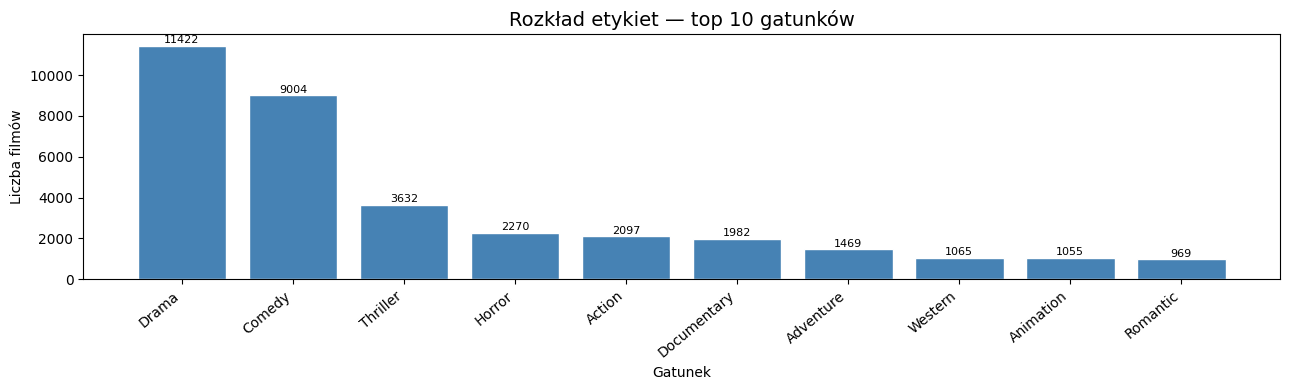

In [ ]:
label_counts = Counter(df['genre'])
genres_sorted = [g for g in top_genres_list]
counts_sorted = [label_counts[g] for g in genres_sorted]

plt.figure(figsize=(13, 4))
bars = plt.bar(genres_sorted, counts_sorted, color='steelblue', edgecolor='white')
plt.title(f'Rozkład etykiet — top {top_10} gatunków', fontsize=14)
plt.xlabel('Gatunek')
plt.ylabel('Liczba filmów')
plt.xticks(rotation=40, ha='right')
for bar, cnt in zip(bars, counts_sorted):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
             str(cnt), ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('05_label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Embeddingi GloVe — reprezentacja sekwencyjna

Wczytujemy GloVe 50D.  
Każdy opis reprezentujemy jako sekwencję tokenów (tensor `[100 50]`), przez co RNN może uwzględniać kolejność słów.


In [ ]:
from google.colab import files
files.upload()

In [ ]:
glove = {}
with open("/content/glove.6B.50d.txt", "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split()
        word  = parts[0]
        vector = torch.tensor([float(x) for x in parts[1:]])
        glove[word] = vector

print(f"Wczytano {len(glove):,} wektorów | wymiar: {glove['film'].shape[0]}")

Wczytano 400,000 wektorów | wymiar: 50


In [ ]:
def text_to_sequence(tokens, max_len=100):
    vectors = [glove[t] for t in tokens if t in glove][:max_len]
    seq = torch.zeros(max_len, 50)
    for i, v in enumerate(vectors):
        seq[i] = v
    return seq

test_seq = text_to_sequence(df.iloc[0]['tokens'])
print(f"Kształt sekwencji: {test_seq.shape}")

Kształt sekwencji: torch.Size([100, 50])


In [ ]:
X_seq_list = [text_to_sequence(tokens) for tokens in df['tokens']]
X_seq = torch.stack(X_seq_list)

print(f"Macierz X (sekwencje): {X_seq.shape}")
print(f"Wektor Y:              {Y.shape}")

def text_to_embedding(tokens):
    vectors = [glove[t] for t in tokens if t in glove]
    if not vectors:
        return torch.zeros(50)
    return torch.stack(vectors).mean(dim=0)

X_avg_list = [text_to_embedding(tokens) for tokens in df['tokens']]
X_avg = torch.stack(X_avg_list)
print(f"Macierz X (średnia):   {X_avg.shape}")

Macierz X (sekwencje): torch.Size([34965, 100, 50])
Wektor Y:              torch.Size([34965])
Macierz X (średnia):   torch.Size([34965, 50])


## 6. Podział na zbiory i DataLoader

Podział **70% trening / 15% walidacja / 15% test**

Przygotowujemy dwa zestawy DataLoaderów:
- `*_loader` — do Modelu 1 (GloVe avg) i Modelu 2 (RNN/GRU)
- `bert_*_loader` — do Modelu 3 (BERT), z tokenizacją BERT


In [ ]:
Y_np = Y.numpy()
idx = np.arange(len(Y_np))

idx_train, idx_rest, y_train, y_rest = train_test_split(idx, Y_np, test_size=0.30, random_state=42)
idx_valid, idx_test, y_valid, y_test = train_test_split(idx_rest, y_rest, test_size=0.50, random_state=42)

#Model 1
X_train_avg = X_avg[idx_train]
X_valid_avg = X_avg[idx_valid]
X_test_avg  = X_avg[idx_test]

#Model 2 RNN
X_train_seq = X_seq[idx_train]
X_valid_seq = X_seq[idx_valid]
X_test_seq  = X_seq[idx_test]

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_valid_t = torch.tensor(y_valid, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

print(f"Trening:   {len(idx_train):,} próbek")
print(f"Walidacja: {len(idx_valid):,} próbek")
print(f"Test:      {len(idx_test):,} próbek")

Trening:   24,475 próbek
Walidacja: 5,245 próbek
Test:      5,245 próbek


In [ ]:
train_loader_avg = DataLoader(TensorDataset(X_train_avg, y_train_t), batch_size=50, shuffle=True)
valid_loader_avg = DataLoader(TensorDataset(X_valid_avg, y_valid_t), batch_size=50)
test_loader_avg  = DataLoader(TensorDataset(X_test_avg,  y_test_t),  batch_size=50)

train_loader_seq = DataLoader(TensorDataset(X_train_seq, y_train_t), batch_size=50, shuffle=True)
valid_loader_seq = DataLoader(TensorDataset(X_valid_seq, y_valid_t), batch_size=50)
test_loader_seq  = DataLoader(TensorDataset(X_test_seq,  y_test_t),  batch_size=50)

print(f"Batch size: 50 ")

Batch size: 50 


In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

class BertGenreDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

texts = df['description'].tolist()

bert_train = BertGenreDataset([texts[i] for i in idx_train], y_train, tokenizer)
bert_valid = BertGenreDataset([texts[i] for i in idx_valid], y_valid, tokenizer)
bert_test  = BertGenreDataset([texts[i] for i in idx_test],  y_test,  tokenizer)

bert_train_loader = DataLoader(bert_train, batch_size=16, shuffle=True)
bert_valid_loader = DataLoader(bert_valid, batch_size=16)
bert_test_loader  = DataLoader(bert_test,  batch_size=16)

print(f"BERT batche w treningu: {len(bert_train_loader)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


BERT batche w treningu: 1530


## 7. Modele neuronowe

- **Model 1** — prosta warstwa liniowa na GloVe avg (`nn.Linear`) — *baseline*
- **Model 2** — GRU na sekwencjach GloVe (uwzględnia kolejność słów)
- **Model 3** — BERT `bert-base-uncased` z fine-tuningiem (HuggingFace)

Klasyfikacja **jednoetykietowa** — `CrossEntropyLoss` + `argmax`.  
Pytanie badawcze: *na ile model zbudowany od podstaw (GRU + GloVe) zbliża się do pretrenowanego BERT-a?*


In [ ]:
#model 1: prosta warstwa liniowa. Jako wejście: 50D (GloVe), Wyjście: 10 (liczba gatunków)
model1 = nn.Linear(50, top_10).to(device)

print("Model 1 (Linear):")
print(model1)
print(f"Parametrów: {sum(p.numel() for p in model1.parameters()):,}")

Model 1 (Linear):
Linear(in_features=50, out_features=10, bias=True)
Parametrów: 510


In [ ]:
#model 2: GRU na sekwencjach GloVe
class GRUClassifier(nn.Module):
    def __init__(self, input_dim=50, hidden_dim=128, num_layers=2,
                 output_dim=top_10, dropout=0.3):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, x):
        _, hidden = self.gru(x)
        hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        out = self.dropout(hidden)
        return self.fc(out)

model2 = GRUClassifier().to(device)
print("Model 2 (GRU bidirectional):")
print(model2)
print(f"Parametrów: {sum(p.numel() for p in model2.parameters()):,}")

Model 2 (GRU bidirectional):
GRUClassifier(
  (gru): GRU(50, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=10, bias=True)
)
Parametrów: 437,258


In [ ]:
#model 3: BERT fine-tuning
model3 = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=top_10
).to(device)

print("Model 3: BERT bert-base-uncased")
print(f"Parametrów: {sum(p.numel() for p in model3.parameters()):,}")

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model 3: BERT bert-base-uncased
Parametrów: 109,489,930


In [ ]:
def get_accuracy(model, data_loader, is_bert=False):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for batch in data_loader:
            if is_bert:
                ids  = batch['input_ids'].to(device)
                mask = batch['attention_mask'].to(device)
                y_b  = batch['label'].to(device)
                out  = model(ids, attention_mask=mask).logits
            else:
                X_b, y_b = batch
                X_b, y_b = X_b.to(device), y_b.to(device)
                out = model(X_b)
            correct += (torch.argmax(out, dim=1) == y_b).sum().item()
            total   += y_b.size(0)
    return correct / total

def get_topk_accuracy(model, data_loader, k=3, is_bert=False):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for batch in data_loader:
            if is_bert:
                ids  = batch['input_ids'].to(device)
                mask = batch['attention_mask'].to(device)
                y_b  = batch['label'].to(device)
                out  = model(ids, attention_mask=mask).logits
            else:
                X_b, y_b = batch
                X_b, y_b = X_b.to(device), y_b.to(device)
                out = model(X_b)
            topk_idx = torch.topk(out, k, dim=1).indices
            correct += (topk_idx == y_b.unsqueeze(1)).any(dim=1).sum().item()
            total   += y_b.size(0)
    return correct / total

In [ ]:
def train_network(model, train_loader, valid_loader, num_epochs=50,
                  learning_rate=1e-3, is_bert=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    hist = {'train_loss': [], 'valid_loss': [],
            'train_acc':  [], 'valid_acc':  [],
            'train_top3': [], 'valid_top3': []}

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for batch in train_loader:
            if is_bert:
                ids  = batch['input_ids'].to(device)
                mask = batch['attention_mask'].to(device)
                y_b  = batch['label'].to(device)
                optimizer.zero_grad()
                loss = model(ids, attention_mask=mask, labels=y_b).loss
            else:
                X_b, y_b = batch
                X_b, y_b = X_b.to(device), y_b.to(device)
                optimizer.zero_grad()
                loss = criterion(model(X_b), y_b)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in valid_loader:
                if is_bert:
                    ids  = batch['input_ids'].to(device)
                    mask = batch['attention_mask'].to(device)
                    y_b  = batch['label'].to(device)
                    val_loss += model(ids, attention_mask=mask, labels=y_b).loss.item()
                else:
                    X_b, y_b = batch
                    X_b, y_b = X_b.to(device), y_b.to(device)
                    val_loss += criterion(model(X_b), y_b).item()

        hist['train_loss'].append(running_loss / len(train_loader))
        hist['valid_loss'].append(val_loss     / len(valid_loader))
        hist['train_acc'].append(get_accuracy(model, train_loader, is_bert))
        hist['valid_acc'].append(get_accuracy(model, valid_loader, is_bert))
        hist['train_top3'].append(get_topk_accuracy(model, train_loader, k=3, is_bert=is_bert))
        hist['valid_top3'].append(get_topk_accuracy(model, valid_loader, k=3, is_bert=is_bert))

        if (epoch + 1) % 5 == 0:
            print(f"Epoka {epoch+1:3d}/{num_epochs} | "
                  f"Train Loss: {hist['train_loss'][-1]:.4f} | "
                  f"Valid Loss: {hist['valid_loss'][-1]:.4f} | "
                  f"Valid Acc: {hist['valid_acc'][-1]:.4f} | "
                  f"Valid Top-3: {hist['valid_top3'][-1]:.4f}")

    return hist

## 8. Trening i porównanie modeli

In [ ]:
print("TRENING: Model 1 — GloVe avg (baseline)")
hist1 = train_network(model1, train_loader_avg, valid_loader_avg,
                      num_epochs=50, learning_rate=1e-3)

TRENING: Model 1 — GloVe avg (baseline)
Epoka   5/50 | Train Loss: 1.3589 | Valid Loss: 1.3767 | Valid Acc: 0.4908 | Valid Top-3: 0.8576
Epoka  10/50 | Train Loss: 1.3519 | Valid Loss: 1.3717 | Valid Acc: 0.4923 | Valid Top-3: 0.8578
Epoka  15/50 | Train Loss: 1.3484 | Valid Loss: 1.3693 | Valid Acc: 0.4953 | Valid Top-3: 0.8570
Epoka  20/50 | Train Loss: 1.3454 | Valid Loss: 1.3665 | Valid Acc: 0.4969 | Valid Top-3: 0.8599
Epoka  25/50 | Train Loss: 1.3439 | Valid Loss: 1.3659 | Valid Acc: 0.4972 | Valid Top-3: 0.8583
Epoka  30/50 | Train Loss: 1.3423 | Valid Loss: 1.3650 | Valid Acc: 0.5014 | Valid Top-3: 0.8599
Epoka  35/50 | Train Loss: 1.3414 | Valid Loss: 1.3646 | Valid Acc: 0.4944 | Valid Top-3: 0.8606
Epoka  40/50 | Train Loss: 1.3406 | Valid Loss: 1.3642 | Valid Acc: 0.4957 | Valid Top-3: 0.8591
Epoka  45/50 | Train Loss: 1.3399 | Valid Loss: 1.3652 | Valid Acc: 0.4936 | Valid Top-3: 0.8591
Epoka  50/50 | Train Loss: 1.3393 | Valid Loss: 1.3637 | Valid Acc: 0.4978 | Valid Top-

In [ ]:
print("TRENING: Model 2 — GRU na sekwencjach GloVe")
hist2 = train_network(model2, train_loader_seq, valid_loader_seq,
                      num_epochs=50, learning_rate=1e-3)

TRENING: Model 2 — GRU na sekwencjach GloVe
Epoka   5/50 | Train Loss: 0.0854 | Valid Loss: 3.3528 | Valid Acc: 0.5169 | Valid Top-3: 0.8501
Epoka  10/50 | Train Loss: 0.0788 | Valid Loss: 3.3151 | Valid Acc: 0.5296 | Valid Top-3: 0.8633
Epoka  15/50 | Train Loss: 0.0793 | Valid Loss: 3.2748 | Valid Acc: 0.5274 | Valid Top-3: 0.8587
Epoka  20/50 | Train Loss: 0.0729 | Valid Loss: 3.3401 | Valid Acc: 0.5226 | Valid Top-3: 0.8559
Epoka  25/50 | Train Loss: 0.0678 | Valid Loss: 3.3149 | Valid Acc: 0.5184 | Valid Top-3: 0.8530
Epoka  30/50 | Train Loss: 0.0712 | Valid Loss: 3.4279 | Valid Acc: 0.5153 | Valid Top-3: 0.8503
Epoka  35/50 | Train Loss: 0.0674 | Valid Loss: 3.3940 | Valid Acc: 0.5237 | Valid Top-3: 0.8582
Epoka  40/50 | Train Loss: 0.0794 | Valid Loss: 3.5104 | Valid Acc: 0.5224 | Valid Top-3: 0.8524
Epoka  45/50 | Train Loss: 0.0821 | Valid Loss: 3.3765 | Valid Acc: 0.5209 | Valid Top-3: 0.8566
Epoka  50/50 | Train Loss: 0.0756 | Valid Loss: 3.3995 | Valid Acc: 0.5276 | Valid 

In [ ]:
print("TRENING: Model 3 — BERT fine-tuning (bert-base-uncased)")
hist3 = train_network(model3, bert_train_loader, bert_valid_loader,
                      num_epochs=5, learning_rate=2e-5, is_bert=True)

TRENING: Model 3 — BERT fine-tuning (bert-base-uncased)
Epoka   5/5 | Train Loss: 0.0955 | Valid Loss: 1.8532 | Valid Acc: 0.6185 | Valid Top-3: 0.9085


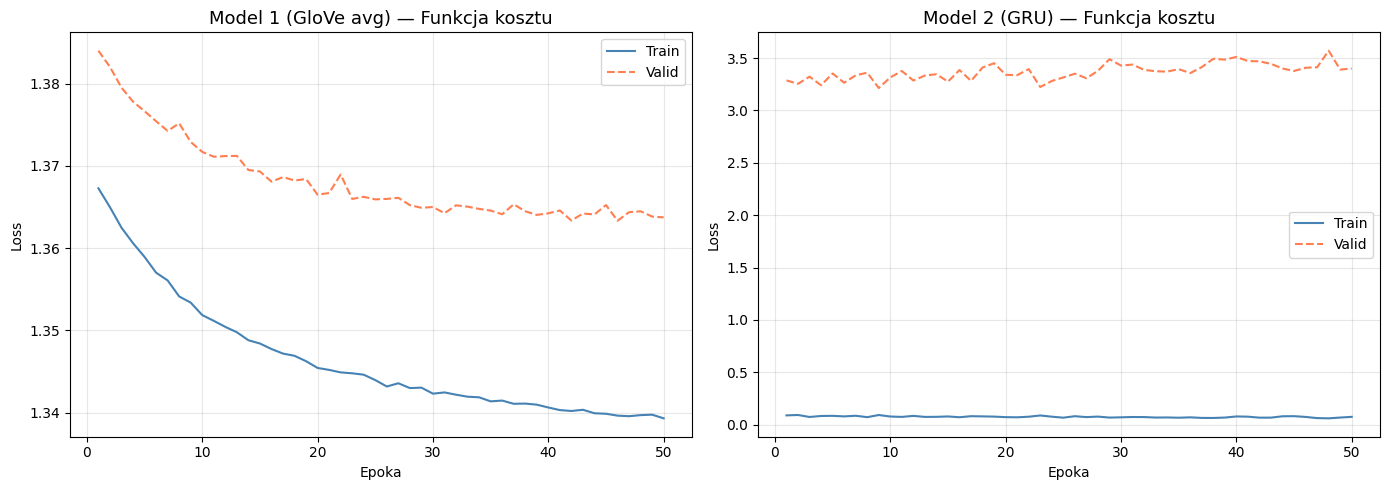

In [ ]:
#krzywe kosztu — Modele 1 i 2
epochs_g = range(1, num_epochs_glove + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, hist, title in zip(axes,
                            [hist1, hist2],
                            ['Model 1 (GloVe avg)', 'Model 2 (GRU)']):
    ax.plot(epochs_g, hist['train_loss'], label='Train', color='steelblue')
    ax.plot(epochs_g, hist['valid_loss'], label='Valid', color='coral', linestyle='--')
    ax.set_title(f'{title} — Funkcja kosztu', fontsize=13)
    ax.set_xlabel('Epoka')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

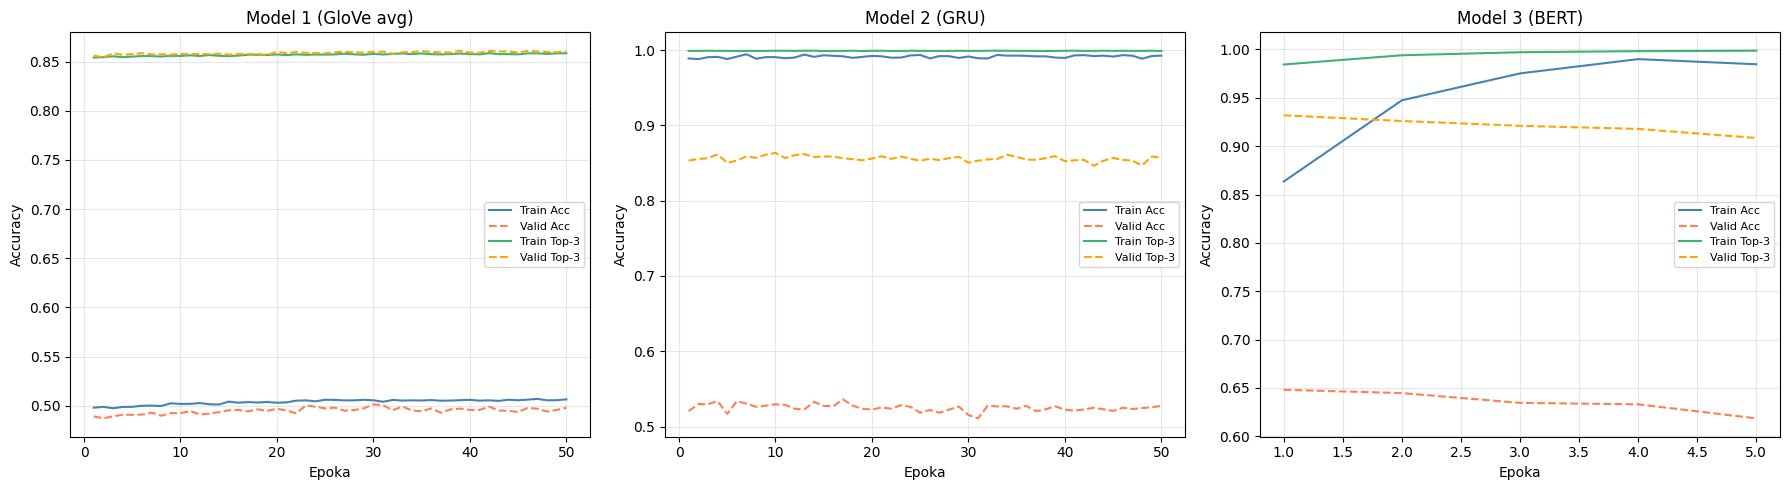

In [ ]:
#krzywe accuracy — Modele 1, 2, 3
epochs_b = range(1, num_epochs_bert + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, hist, ep, title in zip(
        axes,
        [hist1, hist2, hist3],
        [epochs_g, epochs_g, epochs_b],
        ['Model 1 (GloVe avg)', 'Model 2 (GRU)', 'Model 3 (BERT)']):
    ax.plot(ep, hist['train_acc'],  label='Train Acc',  color='steelblue')
    ax.plot(ep, hist['valid_acc'],  label='Valid Acc',  color='coral', linestyle='--')
    ax.plot(ep, hist['train_top3'], label='Train Top-3', color='mediumseagreen')
    ax.plot(ep, hist['valid_top3'], label='Valid Top-3', color='orange', linestyle='--')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Epoka')
    ax.set_ylabel('Accuracy')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
acc1  = get_accuracy(model1, test_loader_avg)
acc2  = get_accuracy(model2, test_loader_seq)
acc3  = get_accuracy(model3, bert_test_loader, is_bert=True)
top1  = get_topk_accuracy(model1, test_loader_avg, k=3)
top2  = get_topk_accuracy(model2, test_loader_seq, k=3)
top3  = get_topk_accuracy(model3, bert_test_loader, k=3, is_bert=True)

print("WYNIKI NA ZBIORZE TESTOWYM")
print(f"\n{'Model':<28} {'Accuracy':>10} {'Top-3 Acc':>10}")
print(f"{'Model 1 (GloVe avg — baseline)':<28} {acc1:>10.4f} {top1:>10.4f}")
print(f"{'Model 2 (GRU + GloVe)':<28} {acc2:>10.4f} {top2:>10.4f}")
print(f"{'Model 3 (BERT fine-tuning)':<28} {acc3:>10.4f} {top3:>10.4f}")
print(f"\nRóżnica GRU vs BERT: {acc2-acc3:+.4f}")

WYNIKI NA ZBIORZE TESTOWYM

Model                          Accuracy  Top-3 Acc
Model 1 (GloVe avg — baseline)     0.5117     0.8524
Model 2 (GRU + GloVe)            0.5199     0.8517
Model 3 (BERT fine-tuning)       0.6194     0.9087

Różnica GRU vs BERT: -0.0995


In [ ]:
for model, loader, is_bert, name in [
    (model1, test_loader_avg, False, "Model 1 (GloVe avg)"),
    (model2, test_loader_seq, False, "Model 2 (GRU)"),
    (model3, bert_test_loader, True, "Model 3 (BERT)"),
]:
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            if is_bert:
                ids  = batch['input_ids'].to(device)
                mask = batch['attention_mask'].to(device)
                y_b  = batch['label']
                out  = model(ids, attention_mask=mask).logits.cpu()
            else:
                X_b, y_b = batch
                out = model(X_b.to(device)).cpu()
            all_preds.append(torch.argmax(out, dim=1))
            all_labels.append(y_b)

    preds  = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()

    print(f"\nRaport: {name}")
    print(classification_report(labels, preds,
                                 target_names=top_genres_list, zero_division=0))


Raport: Model 1 (GloVe avg)
              precision    recall  f1-score   support

       Drama       0.52      0.69      0.59      1758
      Comedy       0.51      0.59      0.55      1330
    Thriller       0.47      0.29      0.36       526
      Horror       0.50      0.30      0.37       362
      Action       0.39      0.34      0.36       292
 Documentary       0.67      0.53      0.59       296
   Adventure       0.39      0.23      0.28       208
     Western       0.56      0.52      0.54       166
   Animation       0.45      0.24      0.31       159
    Romantic       0.44      0.05      0.09       148

    accuracy                           0.51      5245
   macro avg       0.49      0.38      0.41      5245
weighted avg       0.50      0.51      0.49      5245


Raport: Model 2 (GRU)
              precision    recall  f1-score   support

       Drama       0.55      0.63      0.58      1758
      Comedy       0.55      0.57      0.56      1330
    Thriller       0.44   

## 8b. Klasyfikacja rozszerzona — top-3

Model podaje trzy najbardziej prawdopodobne gatunki wraz z prawdopodobieństwami


In [ ]:
def predict_top3(text, model, tokenizer=None, is_bert=False, is_rnn=False, k=3):
    model.eval()
    with torch.no_grad():
        if is_bert:
            enc = tokenizer(text, return_tensors='pt',
                            max_length=128, truncation=True, padding='max_length')
            out = model(enc['input_ids'].to(device),
                        attention_mask=enc['attention_mask'].to(device)).logits
        elif is_rnn:
            tokens = preprocess(text)
            vec = text_to_sequence(tokens).unsqueeze(0).to(device)
            out = model(vec)
        else:
            tokens = preprocess(text)
            vec = text_to_embedding(tokens).unsqueeze(0).to(device)
            out = model(vec)
        probs = torch.softmax(out, dim=1).squeeze(0).cpu()
        top_vals, top_idx = torch.topk(probs, k)
    return [(idx_to_genre[i.item()], round(v.item(), 3))
            for i, v in zip(top_idx, top_vals)]

print(f"{'Film':<35} {'Model 1 (avg)':<35} {'Model 2 (GRU)':<35} {'Model 3 (BERT)'}")
for _, row in df.sample(5, random_state=7).iterrows():
    t1 = predict_top3(row['description'], model1)
    t2 = predict_top3(row['description'], model2, is_rnn=True)
    t3 = predict_top3(row['description'], model3, tokenizer, is_bert=True)
    fmt = lambda lst: "  |  ".join(f"{g}({p:.2f})" for g, p in lst)
    print(f"{row['title'][:33]:<35} {fmt(t1):<35} {fmt(t2):<35} {fmt(t3)}")

Film                                Model 1 (avg)                       Model 2 (GRU)                       Model 3 (BERT)
The One and Only                    Drama(0.52)  |  Comedy(0.29)  |  Documentary(0.06) Comedy(0.96)  |  Romantic(0.02)  |  Drama(0.02) Comedy(1.00)  |  Drama(0.00)  |  Romantic(0.00)
Mr. Wong Detective                  Action(0.62)  |  Thriller(0.25)  |  Comedy(0.03) Thriller(1.00)  |  Action(0.00)  |  Drama(0.00) Thriller(1.00)  |  Drama(0.00)  |  Action(0.00)
Hope Springs                        Comedy(0.64)  |  Drama(0.18)  |  Romantic(0.08) Comedy(1.00)  |  Drama(0.00)  |  Romantic(0.00) Comedy(0.86)  |  Drama(0.14)  |  Romantic(0.00)
Crossing the Bridge - The Sound o   Drama(0.29)  |  Comedy(0.29)  |  Documentary(0.12) Documentary(1.00)  |  Drama(0.00)  |  Comedy(0.00) Documentary(0.58)  |  Drama(0.40)  |  Animation(0.00)
Rock Hudson's Home Movies           Documentary(0.42)  |  Comedy(0.23)  |  Thriller(0.12) Documentary(1.00)  |  Drama(0.00)  |  Comedy(0.00) 

## 9. Analiza grafowa — semantyczny graf filmów

- **Wierzchołki** = filmy
- **Krawędź** = podobieństwo cosinusowe opisów > próg

Analizujemy:
wykrywanie społeczności, współczynnik grupowania, najkrótsza ścieżka


In [ ]:
n_sample  = 400
threshold = 0.80

random.seed(42)
idx_sample    = random.sample(range(len(df)), n_sample)
X_sample = X_avg[idx_sample].numpy()
genres_sample = [df.iloc[i]['genre'] for i in idx_sample]
titles_sample = [str(df.iloc[i]['title']) for i in idx_sample]

print(f"Filmów w grafie: {n_sample} | Próg: {threshold}")

Filmów w grafie: 400 | Próg: 0.8


In [ ]:
sim_matrix = cosine_similarity(X_sample)

G = nx.Graph()
for i in range(n_sample):
    G.add_node(i, title=titles_sample[i], genre=genres_sample[i])

for i in range(n_sample):
    for j in range(i + 1, n_sample):
        if sim_matrix[i][j] > threshold:
            G.add_edge(i, j, weight=float(sim_matrix[i][j]))

print(f"Wierzchołków: {G.number_of_nodes()}")
print(f"Krawędzi:     {G.number_of_edges()}")
print(f"Średni stopień:  {np.mean([d for _, d in G.degree()]):.2f}")

Wierzchołków: 400
Krawędzi:     69463
Średni stopień:  347.31


/tmp/ipykernel_4089/1045338916.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


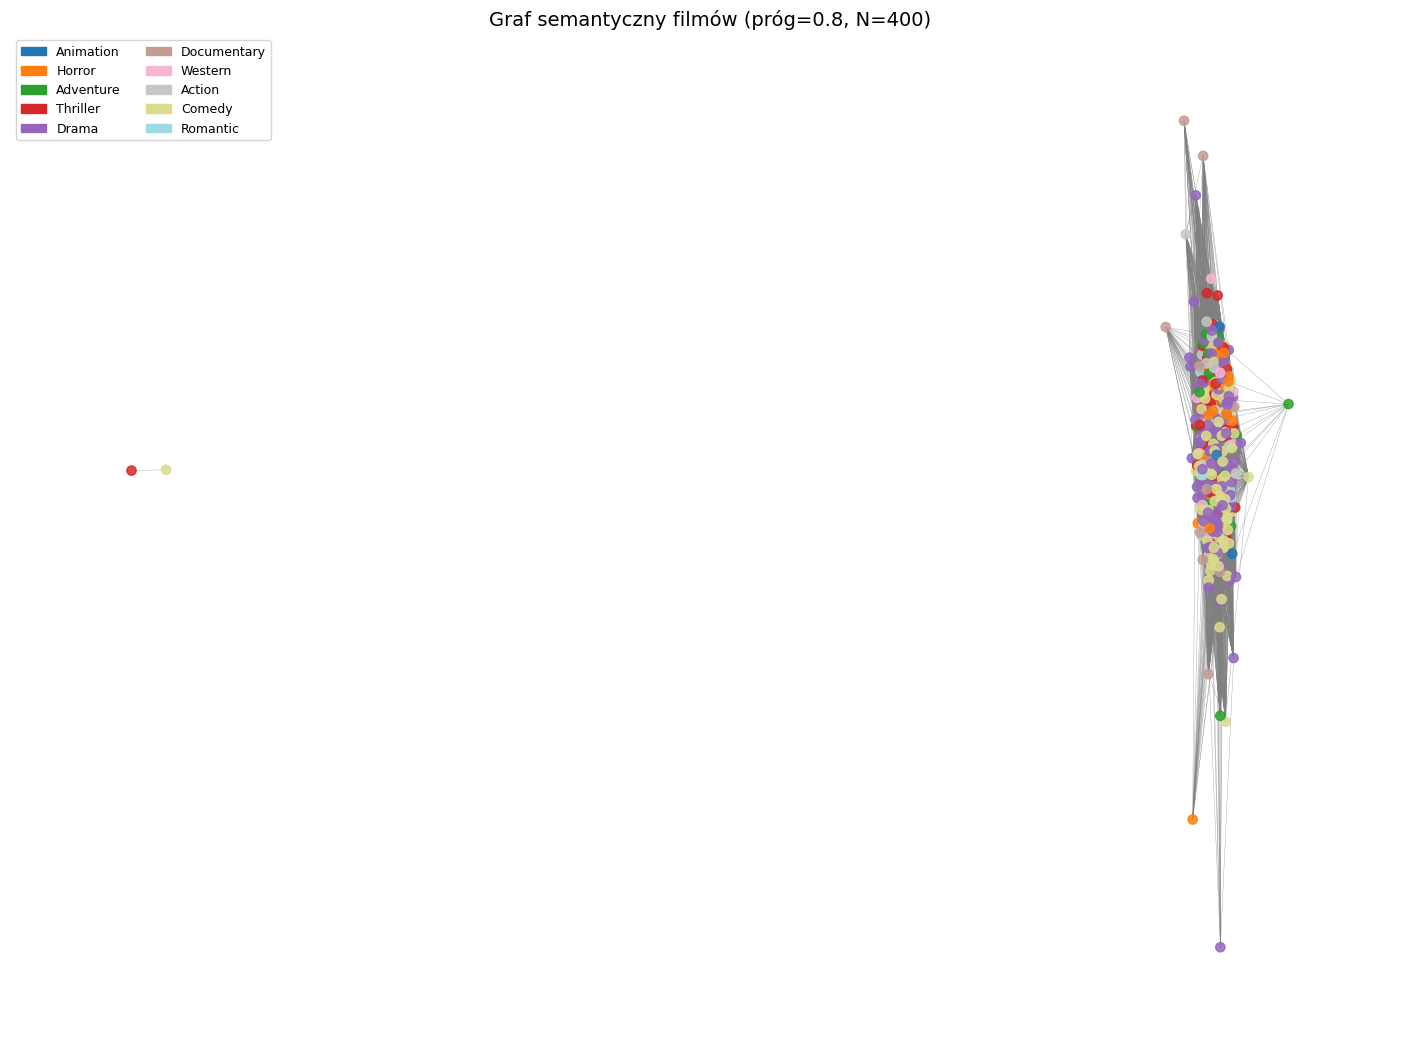

In [ ]:
unique_genres_g = list(set(genres_sample))
cmap = plt.cm.tab20(np.linspace(0, 1, len(unique_genres_g)))
genre_color = {g: cmap[i] for i, g in enumerate(unique_genres_g)}
node_colors = [genre_color[G.nodes[n]['genre']] for n in G.nodes()]

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos,
        node_color=node_colors, node_size=45,
        width=0.25, edge_color='gray', alpha=0.85,
        with_labels=False)

legend_patches = [mpatches.Patch(color=genre_color[g], label=g)
                  for g in unique_genres_g]
plt.legend(handles=legend_patches, loc='upper left', fontsize=9, ncol=2)
plt.title(f'Graf semantyczny filmów (próg={threshold}, N={n_sample})', fontsize=14)
plt.tight_layout()
plt.savefig('08_semantic_graph.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
communities = community.greedy_modularity_communities(G)
print(f"Liczba wykrytych społeczności: {len(communities)}")

#gatunki dominujące w każdej społeczności
for i, comm in enumerate(list(communities)[:8]):
    genre_counter = Counter([G.nodes[n]['genre'] for n in comm])
    top = genre_counter.most_common(3)
    print(f"Społeczność {i+1:2d} ({len(comm):3d} filmów): {top}")

Liczba wykrytych społeczności: 4
Społeczność  1 (188 filmów): [('Drama', 69), ('Comedy', 57), ('Thriller', 24)]
Społeczność  2 (173 filmów): [('Drama', 50), ('Comedy', 38), ('Thriller', 16)]
Społeczność  3 ( 37 filmów): [('Drama', 17), ('Comedy', 11), ('Horror', 2)]
Społeczność  4 (  2 filmów): [('Thriller', 1), ('Comedy', 1)]


/tmp/ipykernel_4089/289004785.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


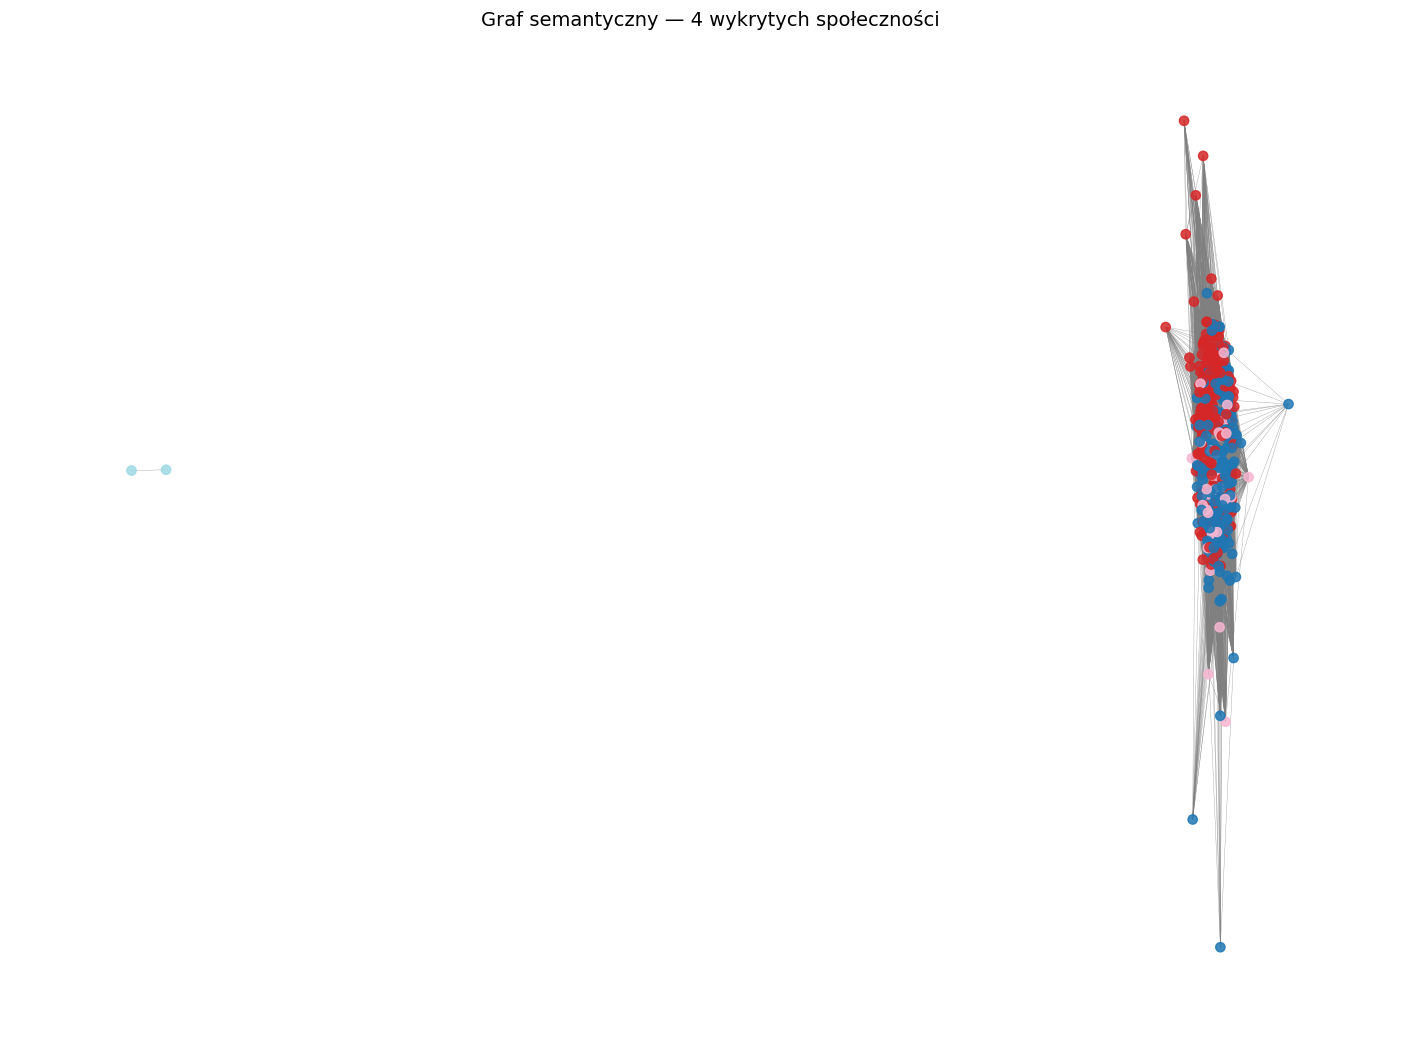

In [ ]:
node_comm = {}
for ci, comm in enumerate(communities):
    for node in comm:
        node_comm[node] = ci

colors_comm = [node_comm[n] for n in G.nodes()]

plt.figure(figsize=(14, 10))
nx.draw(G, pos,
        node_color=colors_comm, cmap=plt.cm.tab20,
        node_size=45, width=0.25, edge_color='gray', alpha=0.85,
        with_labels=False)
plt.title(f'Graf semantyczny — {len(communities)} wykrytych społeczności', fontsize=14)
plt.tight_layout()
plt.savefig('09_communities_graph.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#wsp. grupowania
clustering = nx.average_clustering(G)
print(f"Współczynnik grupowania: {clustering:.4f}")
if clustering > 0.5:
    print(f"Wysoki ({clustering:.2f}) → silne bańki tematyczne w grafie filmów.")
elif clustering > 0.2:
    print(f"Umiarkowany ({clustering:.2f}) → gatunki częściowo przenikają się semantycznie.")
else:
    print(f"Niski ({clustering:.2f}) → słaba struktura grupowania przy tym progu.")

components = list(nx.connected_components(G))
print(f"Komponentów spójnych: {len(components)}")

Współczynnik grupowania: 0.9412
Wysoki (0.94) → silne bańki tematyczne w grafie filmów.
Komponentów spójnych: 2


/tmp/ipykernel_4089/2828996002.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


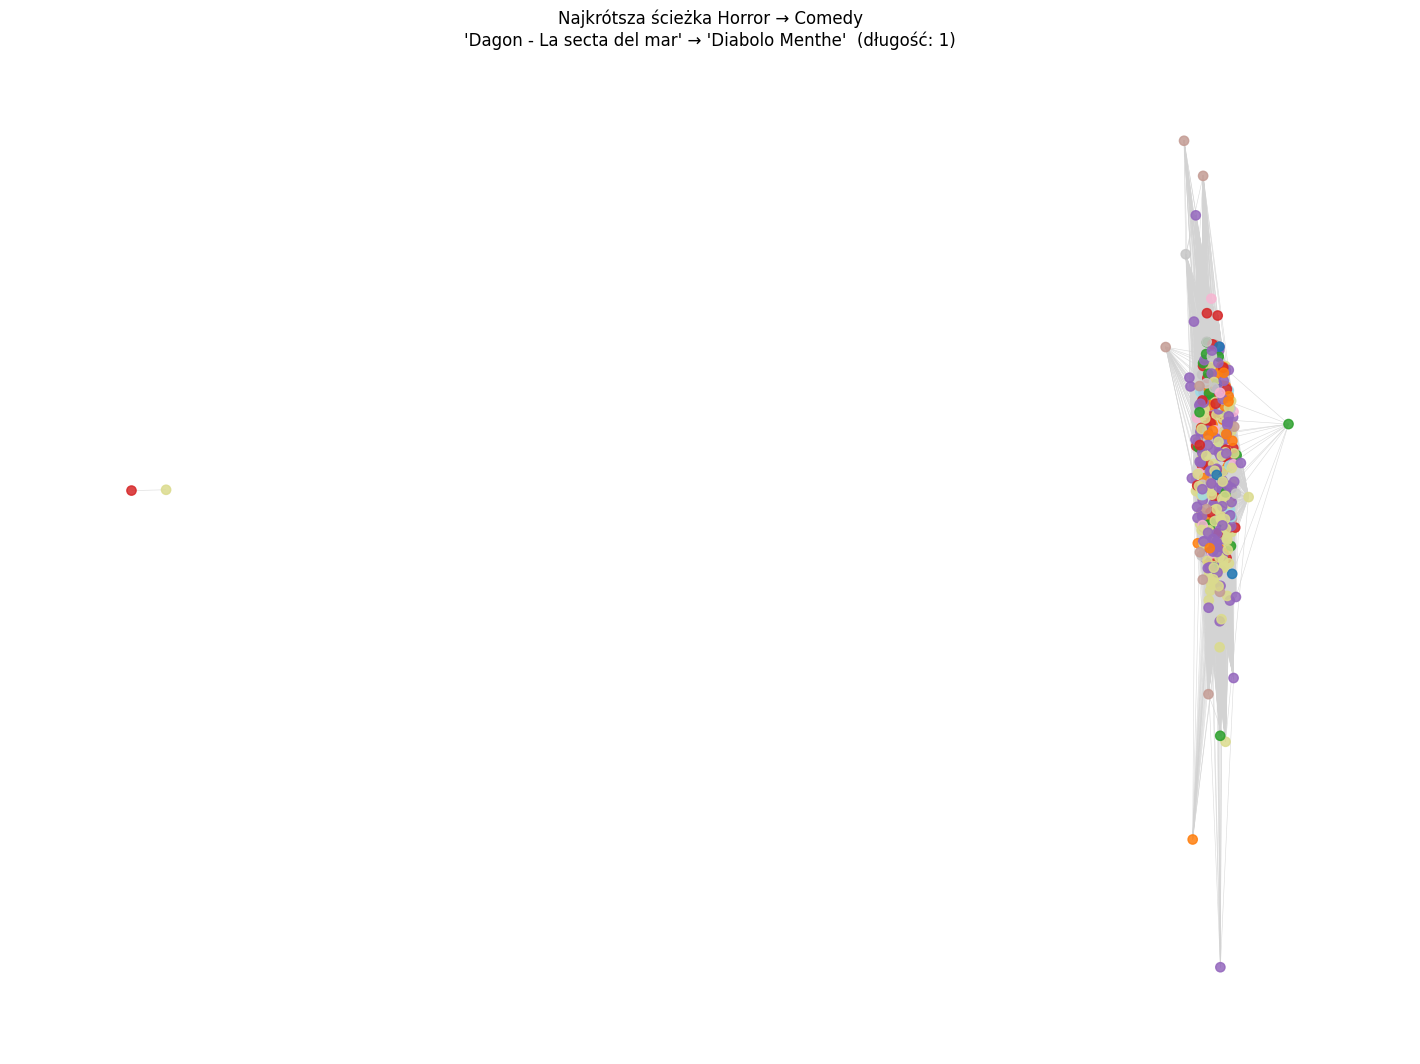

Ścieżka:
  [Horror      ] Dagon - La secta del mar
  [Comedy      ] Diabolo Menthe


In [ ]:
#najkrótsza ścieżka między filmami z różnych gatunków
horror_nodes = [n for n in G.nodes() if G.nodes[n]['genre'] == 'Horror']
comedy_nodes = [n for n in G.nodes() if G.nodes[n]['genre'] == 'Comedy']

if horror_nodes and comedy_nodes:
    src, tgt = horror_nodes[0], comedy_nodes[0]
    try:
        path = nx.shortest_path(G, source=src, target=tgt)
        path_edges  = list(zip(path, path[1:]))
        edge_colors = ['red' if e in path_edges or tuple(reversed(e)) in path_edges
                       else 'lightgray' for e in G.edges()]

        plt.figure(figsize=(14, 10))
        nx.draw(G, pos,
                node_color=node_colors, node_size=45,
                edge_color=edge_colors, width=0.4,
                alpha=0.85, with_labels=False)
        plt.title(
            f"Najkrótsza ścieżka Horror → Comedy\n"
            f"'{titles_sample[src]}' → '{titles_sample[tgt]}'  "
            f"(długość: {len(path)-1})", fontsize=12)
        plt.tight_layout()
        plt.savefig('10_shortest_path.png', dpi=150, bbox_inches='tight')
        plt.show()

        print("Ścieżka:")
        for node in path:
            print(f"  [{G.nodes[node]['genre']:12s}] {titles_sample[node]}")
    except nx.NetworkXNoPath:
        print("Brak ścieżki między tymi węzłami")
else:
    print("Brak Horror lub Comedy w próbce")

## 10. Test generalizacji — dataset TMDB 5000

Sprawdzamy czy modele wytrenowane na FilmTV działają na innym zbiorze danych filmowych bez dodatkowego trenowania


In [ ]:
from google.colab import files
files.upload()

In [ ]:
df_tmdb = pd.read_csv("/content/tmdb_5000_movies.csv")
df_tmdb['genre_list'] = df_tmdb['genres'].apply(
    lambda x: [g['name'] for g in json.loads(x)] if pd.notna(x) else []
)

#pierwszy gatunek z listy jako główny (single-label)
df_tmdb['genre_main'] = df_tmdb['genre_list'].apply(
    lambda gl: next((g for g in gl if g in top_genres_list), None)
)

df_tmdb = (df_tmdb[['title', 'overview', 'genre_main']]
           .rename(columns={'overview': 'description'})
           .dropna()
           .copy())
df_tmdb = df_tmdb[df_tmdb['description'].str.len() > 10].reset_index(drop=True)

print(f"Próbek TMDB: {len(df_tmdb)}")
print(f"Przyklady: {df_tmdb.iloc[0]['title']} → {df_tmdb.iloc[0]['genre_main']}")
print(f"           {df_tmdb.iloc[10]['title']} → {df_tmdb.iloc[10]['genre_main']}")

Próbek TMDB: 4717
Przyklady: Avatar → Action
           Superman Returns → Adventure


In [ ]:
#sprawdzamy czy działa na nowych danych
df_tmdb['tokens'] = df_tmdb['description'].apply(preprocess)
df_tmdb = df_tmdb[df_tmdb['tokens'].map(len) > 0].reset_index(drop=True)

X_tmdb_list = [text_to_embedding(tokens) for tokens in df_tmdb['tokens']]
X_tmdb = torch.stack(X_tmdb_list)
Y_tmdb = torch.tensor([genre_to_idx[g] for g in df_tmdb['genre_main']], dtype=torch.long)

In [ ]:
#BERT DataLoader dla TMDB
tmdb_texts  = df_tmdb['description'].tolist()
tmdb_labels = [genre_to_idx[g] for g in df_tmdb['genre_main']]

bert_tmdb_dataset = BertGenreDataset(tmdb_texts, tmdb_labels, tokenizer)
bert_tmdb_loader  = DataLoader(bert_tmdb_dataset, batch_size=16)

In [ ]:
tmdb_loader_avg = DataLoader(TensorDataset(X_tmdb, Y_tmdb), batch_size=50)

X_tmdb_seq_list = [text_to_sequence(tokens) for tokens in df_tmdb['tokens']]
X_tmdb_seq  = torch.stack(X_tmdb_seq_list)
Y_tmdb_long = torch.tensor(tmdb_labels, dtype=torch.long)
tmdb_loader_seq = DataLoader(TensorDataset(X_tmdb_seq, Y_tmdb_long), batch_size=BATCH)

tmdb_acc1 = get_accuracy(model1, tmdb_loader_avg)
tmdb_acc2 = get_accuracy(model2, tmdb_loader_seq)
tmdb_acc3 = get_accuracy(model3, bert_tmdb_loader, is_bert=True)
tmdb_top1 = get_topk_accuracy(model1, tmdb_loader_avg, k=3)
tmdb_top2 = get_topk_accuracy(model2, tmdb_loader_seq, k=3)
tmdb_top3 = get_topk_accuracy(model3, bert_tmdb_loader, k=3, is_bert=True)

print("GENERALIZACJA — FilmTV (test) vs TMDB (nowe dane)")
print(f"\n{'Model':<28} {'FilmTV Acc':>10} {'TMDB Acc':>10} {'Δ':>6} {'FilmTV Top3':>12} {'TMDB Top3':>10}")
print()

for name, fa, ta, ft, tt in [
    ("Model 1 (GloVe avg)", acc1, tmdb_acc1, top1, tmdb_top1),
    ("Model 2 (GRU)",       acc2, tmdb_acc2, top2, tmdb_top2),
    ("Model 3 (BERT)",      acc3, tmdb_acc3, top3, tmdb_top3),
]:
    print(f"{name:<28} {fa:>10.3f} {ta:>10.3f} {ta-fa:>+6.3f} {ft:>12.3f} {tt:>10.3f}")

GENERALIZACJA — FilmTV (test) vs TMDB (nowe dane)

Model                        FilmTV Acc   TMDB Acc      Δ  FilmTV Top3  TMDB Top3

Model 1 (GloVe avg)               0.512      0.427 -0.085        0.852      0.791
Model 2 (GRU)                     0.520      0.439 -0.081        0.852      0.799
Model 3 (BERT)                    0.619      0.529 -0.091        0.909      0.863
